# Неделя 17. TensorFlow/Keras: модель, compile и обучение по batch

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 27 минут guided comparison; подробный повтор — вне занятий. На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** обучить настоящую tf.keras сеть на том же локальном наборе, понять from_logits и GradientTape, выбрать validation checkpoint и проверить прогнозы.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_17_backprop_frameworks'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Локальные digits 8×8 и единая разбивка

Одна строка — 64 пикселя и цифра 0…9. Известный диапазон пикселя 0…16
позволяет делить на 16 без оценки статистик по данным. Сначала 20% test,
затем 25% оставшихся строк на validation: примерно **60/20/20**.
`sample_id` и target исключены из X. Все три лабораторные недели используют
одинаковые индексы; test не выбирает число эпох.


In [2]:
df = pd.read_csv(DATA / "digits_8x8.csv").set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
pixels = df.drop(columns="target")
assert pixels.shape[1] == 64 and pixels.min().min() >= 0 and pixels.max().max() <= 16
all_ids = df.index.to_numpy()
trainval_ids, test_ids = train_test_split(all_ids, test_size=0.2,
    stratify=df.target, random_state=SEED)
train_ids, val_ids = train_test_split(trainval_ids, test_size=0.25,
    stratify=df.loc[trainval_ids, "target"], random_state=SEED + 1)
assert set(train_ids).isdisjoint(val_ids) and set(trainval_ids).isdisjoint(test_ids)
def arrays(ids):
    return (pixels.loc[ids].to_numpy(dtype="float32") / 16.0,
            df.loc[ids, "target"].to_numpy(dtype="int64"))
X_train, y_train = arrays(train_ids)
X_val, y_val = arrays(val_ids)
X_test, y_test = arrays(test_ids)
print({"train": X_train.shape, "validation": X_val.shape, "sealed_test": X_test.shape})


{'train': (1077, 64), 'validation': (360, 64), 'sealed_test': (360, 64)}


## EDA только train: баланс, распределение и изображения

Изображения уже уменьшены до 8×8, поэтому детали потеряны. Нулевые края
встречаются часто. В исходном экспорте нет ID автора почерка: random split
не проверяет перенос на полностью новых авторов. Сравнение framework на одном
seed — учебная иллюстрация, не рейтинг библиотек.


0    107
1    109
2    106
3    109
4    109
5    109
6    109
7    107
8    104
9    108
Name: train_count, dtype: int64

,mean,std,min,max
0,0.000,0.000,0.0,0.000
1,0.019,0.059,0.0,0.500
2,0.323,0.295,0.0,1.000
3,0.738,0.267,0.0,1.000
4,0.745,0.265,0.0,1.000
5,0.374,0.358,0.0,1.000
6,0.089,0.214,0.0,1.000
7,0.009,0.069,0.0,0.938
8,0.000,0.005,0.0,0.125
9,0.128,0.203,0.0,0.938


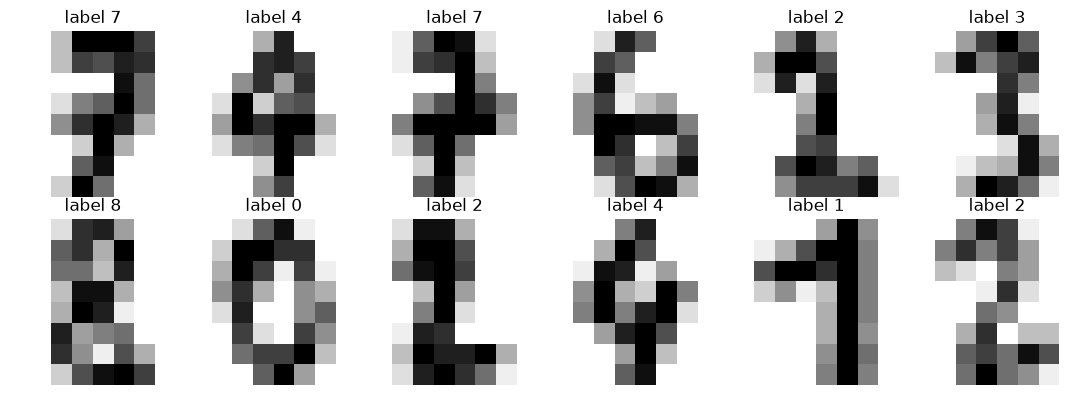

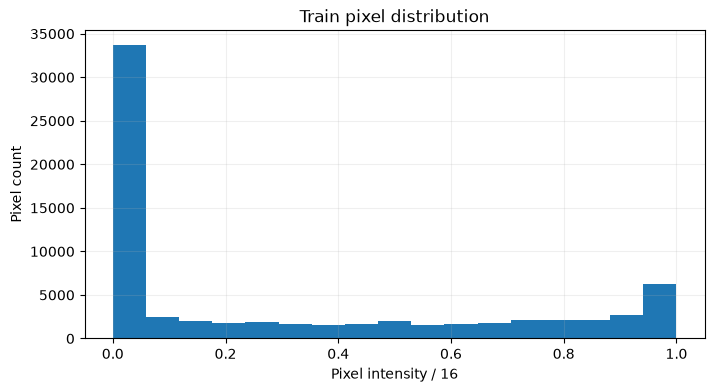

In [3]:
display(pd.Series(y_train).value_counts().sort_index().rename("train_count"))
display(pd.DataFrame(X_train).describe().T[["mean", "std", "min", "max"]].head(12).round(3))
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, image, label in zip(axes.ravel(), X_train[:12], y_train[:12]):
    ax.imshow(image.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"label {label}"); ax.axis("off")
plt.tight_layout(); plt.show()
plt.hist(X_train.ravel(), bins=17)
plt.xlabel("Pixel intensity / 16"); plt.ylabel("Pixel count"); plt.title("Train pixel distribution")
plt.show()


## 1. Реальный TensorFlow backend

Используем `tf.keras`, а не замену на scikit-learn. GPU отключён: пример
рассчитан на обычный CPU. Seeds и число потоков заданы явно. Разные версии
TensorFlow/BLAS всё же могут давать небольшие численные отличия.


In [4]:
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)), tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.1), tf.keras.layers.Dense(10)])
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
              loss=loss_fn, metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
              jit_compile=False)
print("TensorFlow", tf.__version__); model.summary()
assert model.count_params() == (64*32+32)+(32*10+10)


TensorFlow 2.21.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,410 (9.41 KB)

 Trainable params: 2,410 (9.41 KB)

 Non-trainable params: 0 (0.00 B)

## 2. Проверяем autograd через GradientTape

`GradientTape` записывает операции forward pass и возвращает градиенты loss
по trainable variables. `from_logits=True` объединяет softmax и cross-entropy
устойчивым образом. Добавлять ещё один softmax перед этим loss не нужно.


In [5]:
with tf.GradientTape() as tape:
    logits = model(X_train[:64], training=False)
    batch_loss = loss_fn(y_train[:64], logits)
gradients = tape.gradient(batch_loss, model.trainable_variables)
gradient_rows = []
for variable, gradient in zip(model.trainable_variables, gradients):
    assert gradient is not None and bool(tf.reduce_all(tf.math.is_finite(gradient)))
    gradient_rows.append({"variable": variable.name, "shape": str(tuple(variable.shape)),
                          "gradient_norm": float(tf.linalg.global_norm([gradient]))})
display(pd.DataFrame(gradient_rows))
assert tuple(logits.shape) == (64, 10)


,variable,shape,gradient_norm
0,kernel,"(64, 32)",0.614320
1,bias,"(32,)",0.155131
2,kernel,"(32, 10)",0.381154
3,bias,"(10,)",0.165937


## 3. Keras train_on_batch и checkpoint

`train_on_batch` — полноценный Keras training API. Явный batch-цикл показывает,
как устроена эпоха, и работает без дополнительных tf.data thread pools.
`compile` уже задал optimizer/loss; Keras сам делает backward и update.
Validation считаем с `training=False`, чтобы отключить Dropout.


In [6]:
history, best_loss, best_weights, best_epoch = [], float("inf"), None, None
shuffle_rng = np.random.default_rng(SEED)
for epoch in range(1, 25):
    order = shuffle_rng.permutation(len(X_train))
    model.reset_metrics()
    for start in range(0, len(order), 64):
        batch = order[start:start+64]
        batch_metrics = model.train_on_batch(X_train[batch], y_train[batch], return_dict=True)
    # Метрики Keras агрегируются со времени reset_metrics; validation считаем отдельно.
    val_logits = model(X_val, training=False)
    validation_loss = float(loss_fn(y_val, val_logits))
    validation_accuracy = np.mean(np.asarray(val_logits).argmax(axis=1)==y_val)
    history.append({"epoch": epoch, "train_loss": float(batch_metrics["loss"]),
                    "validation_loss": validation_loss, "validation_accuracy": validation_accuracy})
    if validation_loss < best_loss:
        best_loss, best_epoch = validation_loss, epoch
        best_weights = [weight.copy() for weight in model.get_weights()]
model.set_weights(best_weights)
history = pd.DataFrame(history)
assert np.isfinite(history.select_dtypes("number")).all().all()
assert history.train_loss.iloc[-1] < history.train_loss.iloc[0]
print("Restored validation checkpoint epoch:", best_epoch)


Restored validation checkpoint epoch: 24


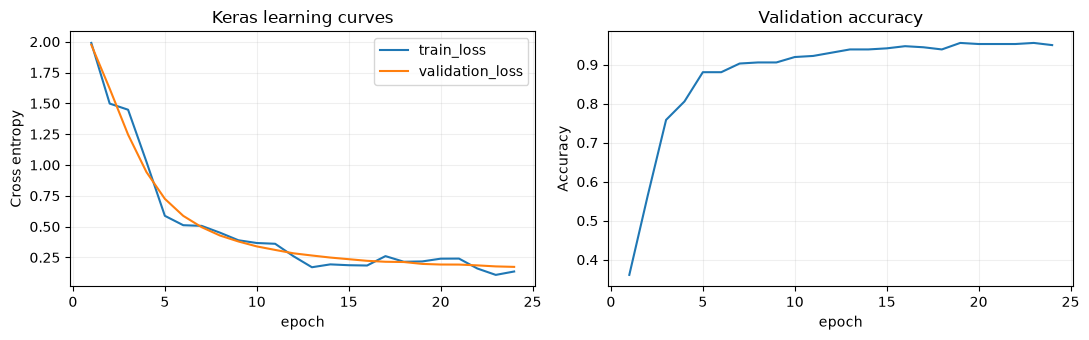

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
history.plot(x="epoch", y=["train_loss", "validation_loss"], ax=axes[0])
axes[0].set(ylabel="Cross entropy", title="Keras learning curves")
history.plot(x="epoch", y="validation_accuracy", ax=axes[1], legend=False)
axes[1].set(ylabel="Accuracy", title="Validation accuracy")
plt.tight_layout(); plt.show()


## 4. Финальный test

Выбор checkpoint завершён до test. Прямой вызов модели удобен для небольшого
локального массива; `tf.nn.softmax` переводит logits в вероятности для отчёта.
Повторный inference с выключенным Dropout должен совпасть.


Baseline test accuracy: 0.1
Keras test accuracy: 0.9611111111111111
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.89      0.86      0.87        36
           2       0.97      1.00      0.99        35
           3       1.00      0.97      0.99        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.88      0.86      0.87        35
           9       0.95      0.97      0.96        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



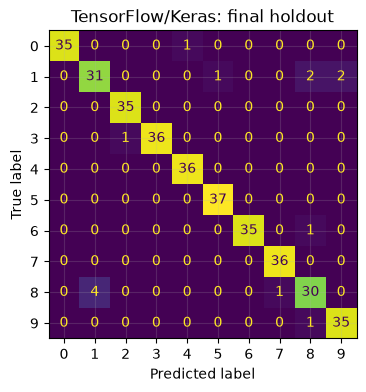

In [8]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
test_logits = model(X_test, training=False)
repeated_logits = model(X_test, training=False)
probability = tf.nn.softmax(test_logits, axis=1).numpy()
prediction = probability.argmax(axis=1)
assert np.allclose(test_logits.numpy(), repeated_logits.numpy(), atol=1e-7)
assert np.allclose(probability.sum(axis=1), 1, atol=1e-6)
assert prediction.shape == y_test.shape
print("Baseline test accuracy:", np.mean(y_test == np.bincount(y_train).argmax()))
print("Keras test accuracy:", accuracy_score(y_test, prediction))
print(classification_report(y_test, prediction, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, colorbar=False)
plt.title("TensorFlow/Keras: final holdout"); plt.show()


## 5. Читаем одно распределение вероятностей

Самый вероятный класс — argmax. Разность первых двух вероятностей — простая
характеристика неоднозначности этого прогноза, но не доверительный интервал
и не оценка ошибки в новых условиях.


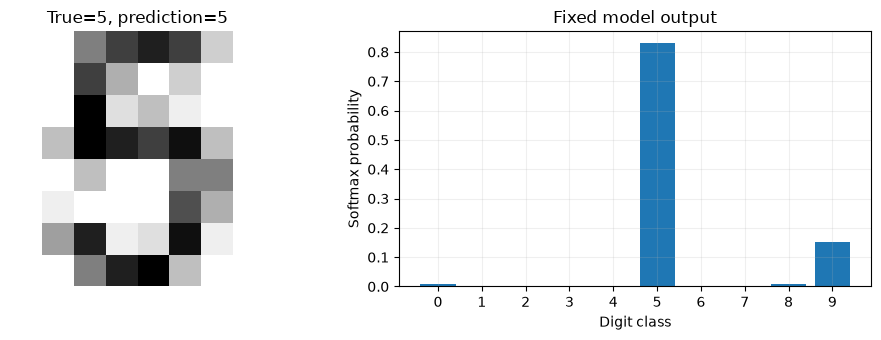

Top-two probability gap: 0.6767812


In [9]:
index = 0
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].imshow(X_test[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title(f"True={y_test[index]}, prediction={prediction[index]}"); axes[0].axis("off")
axes[1].bar(np.arange(10), probability[index]); axes[1].set_xticks(np.arange(10))
axes[1].set(xlabel="Digit class", ylabel="Softmax probability", title="Fixed model output")
plt.tight_layout(); plt.show()
top_two = np.sort(probability[index])[-2:]
print("Top-two probability gap:", top_two[1]-top_two[0])


## Сравните три реализации

NumPy требует явных производных; TensorFlow и PyTorch вычисляют их автоматически.
Keras `compile/train_on_batch` содержит optimizer-step; в PyTorch он записан
в цикле. Оба framework обучили настоящие сети на локальных данных. Разные
инициализации и детали optimizer означают, что метрики не обязаны совпадать.

**Контроль:** объясните `from_logits`, `training=False`, batch, epoch, validation
checkpoint и запрет выбора числа эпох по test.

Источники: [TensorFlow automatic differentiation](https://www.tensorflow.org/guide/autodiff),
[Keras model training APIs](https://keras.io/api/models/model_training_apis/),
[Keras Sequential guide](https://keras.io/guides/sequential_model/),
[TensorFlow beginner tutorial](https://www.tensorflow.org/tutorials/quickstart/beginner).
